# Clustering Analysis

In [1]:
import os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import homogeneity_score
from sklearn.metrics import fowlkes_mallows_score
from sklearn.metrics import adjusted_rand_score
from itertools import combinations
import random

# Setup paths
repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
clean_meta_path = os.path.join(repo_root, "data", "clean", "metadata_clean.parquet")
raw_wave_path = os.path.join(repo_root, "data", "raw", "waveforms.hdf5")

df = pd.read_parquet(clean_meta_path)

# sample_df = df.sample(n=min(1000, len(df)), random_state=42)

# Each trace is 3 x 15001 samples (45003 features once flattened), so the full
# matrix is ~3.4 GB. Fill a preallocated array rather than building a list and
# copying it with np.array(), which needs twice the memory.
with h5py.File(raw_wave_path, "r") as hf:
    dsets = {k: hf["data"][k] for k in hf["data"]}
    n_feat = int(np.prod(next(iter(dsets.values())).shape[1:]))
    X = np.empty((len(df), n_feat), dtype=np.float32)
    keep = []
    for b_val, t_idx in zip(df["bucket"], df["tindex"]):
        b_val, t_idx = str(b_val).strip(), int(t_idx)
        b_key = b_val if b_val.startswith("bucket") else f"bucket{b_val}"
        if b_key in dsets and 0 <= t_idx < dsets[b_key].shape[0]:
            X[len(keep)] = dsets[b_key][t_idx].reshape(-1)
            keep.append(True)
        else:
            keep.append(False)

keep = np.array(keep)
X = X[:keep.sum()]

# Metadata rows aligned with the rows of X (used for the magnitude comparison below)
matched_df = df[keep].reset_index(drop=True)

# Fit PCA. copy=False centers X in place instead of making another ~3.4 GB copy;
# X is not needed after this, so free it.
n_components = 50
pca = PCA(n_components = n_components, copy = False)
X_pca = pca.fit_transform(X)
del X

In [3]:
k_vals = range(2, 15)

inertias = []
silhouette_scores = []

for k in k_vals:
    kmeans = KMeans(n_clusters = k,
                    random_state = 42,
                    n_init = 10)
    cluster_labels = kmeans.fit_predict(X_pca)
    n_clusters_found = len(np.unique(cluster_labels))
    inertias.append(kmeans.inertia_)
    if n_clusters_found > 1:
        score = silhouette_score(X_pca,
                                 cluster_labels,
                                 sample_size = len(X_pca), 
                                 random_state = 42)
    else:
        score = np.nan

    silhouette_scores.append(score)

    print(f"K = {k}, clusters = {n_clusters_found}, ", f"silhouette = {score:.4f}")

K = 2, clusters = 2,  silhouette = 0.9958
K = 3, clusters = 3,  silhouette = 0.9961
K = 4, clusters = 4,  silhouette = 0.9961
K = 5, clusters = 5,  silhouette = 0.9956
K = 6, clusters = 6,  silhouette = 0.9957
K = 7, clusters = 7,  silhouette = 0.9960
K = 8, clusters = 8,  silhouette = 0.9949
K = 9, clusters = 9,  silhouette = 0.9950
K = 10, clusters = 10,  silhouette = 0.9950
K = 11, clusters = 11,  silhouette = 0.9950
K = 12, clusters = 12,  silhouette = 0.9949
K = 13, clusters = 13,  silhouette = 0.9950
K = 14, clusters = 14,  silhouette = 0.9950


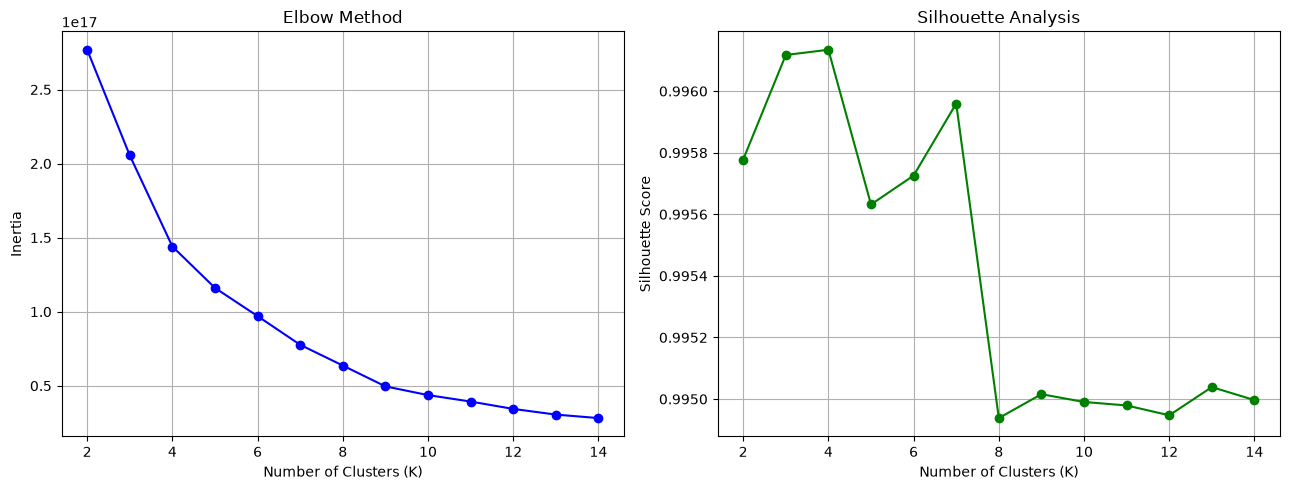

In [4]:
fig, axes = plt.subplots(1, 2, figsize = (13, 5))

# Elbow plot
axes[0].plot(k_vals, inertias, 'bo-')
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method")
axes[0].grid(True)

# Silhouette plot
axes[1].plot(k_vals, silhouette_scores, 'go-')
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Analysis")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [5]:
k = 4

test_kmeans = KMeans(n_clusters = k,
                     random_state = 42,
                     n_init = 10)

test_labels = test_kmeans.fit_predict(X_pca)

print("Unique labels:", np.unique(test_labels))
print("Cluster counts:", np.unique(test_labels, return_counts=True))

Unique labels: [0 1 2 3]
Cluster counts: (array([0, 1, 2, 3], dtype=int32), array([18607,     8,    23,     2]))


In [7]:
magnitude = matched_df["preferred_source_magnitude"]
valid = magnitude.notna()

# Keep only observations with valid magnitude labels
magnitude_bins = pd.qcut(magnitude[valid],
                         q =  4,
                         labels = False,
                         duplicates = "drop")

In [8]:
chosen_k = 4  

# Use only rows with valid magnitude labels
# X_eval = X_pca[valid.to_numpy()]
y_magnitude = magnitude_bins.to_numpy()

kmeans = KMeans(n_clusters = chosen_k,
                random_state = 42,
                n_init = 20)

cluster_labels = kmeans.fit_predict(X_pca)

homogeneity = homogeneity_score(y_magnitude,
                                cluster_labels)

fmi = fowlkes_mallows_score(y_magnitude,
                            cluster_labels)

print("Homogeneity:", homogeneity)
print("Fowlkes-Mallows Index:", fmi)

Homogeneity: 0.0003407064309078771
Fowlkes-Mallows Index: 0.5000607110670321


In [14]:
seeds = random.sample(range(1, 1001), 100)
all_labels = []

for seed in seeds:
    km = KMeans(n_clusters = chosen_k,
                random_state = seed,
                n_init = 10)
    labels = km.fit_predict(X_pca)
    all_labels.append(labels)

# Compare every pair of random seeds
ari_scores = []

for i, j in combinations(range(len(all_labels)), 2):
    ari = adjusted_rand_score(all_labels[i],
                              all_labels[j])
    ari_scores.append(ari)

print("Mean ARI:", np.mean(ari_scores))
print("Standard deviation:", np.std(ari_scores))
print("Minimum ARI:", np.min(ari_scores))
print("Maximum ARI:", np.max(ari_scores))

Mean ARI: 0.9651337484768708
Standard deviation: 0.04563486084102537
Minimum ARI: 0.8208594850887796
Maximum ARI: 1.0


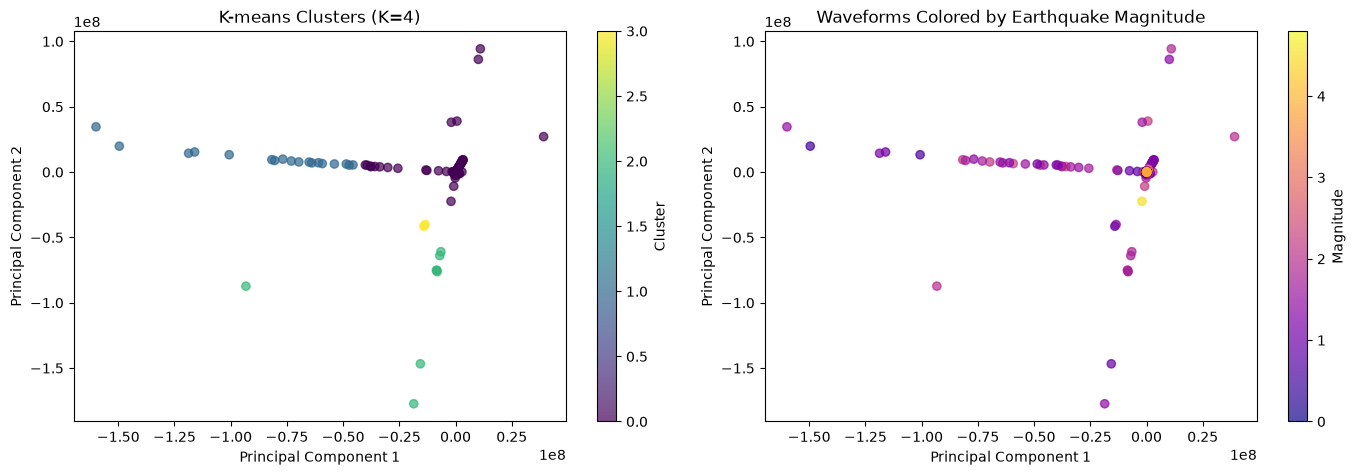

In [12]:
# Reduce the clustering features to 2D for visualization
pca_2d = PCA(n_components = 2)
X_2d = pca_2d.fit_transform(X_pca)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Color by K-means cluster
scatter1 = axes[0].scatter(X_2d[:, 0],
                           X_2d[:, 1],
                           c = cluster_labels,
                           cmap = "viridis",
                           alpha = 0.7)

axes[0].set_title(f"K-means Clusters (K={chosen_k})")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
fig.colorbar(scatter1, ax = axes[0], label = "Cluster")

# Plot 2: Color by actual continuous magnitude
scatter2 = axes[1].scatter(X_2d[:, 0],
                            X_2d[:, 1],
                            c = magnitude[valid].to_numpy(),
                            cmap = "plasma",
                            alpha = 0.7)

axes[1].set_title("Waveforms Colored by Earthquake Magnitude")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
fig.colorbar(scatter2, ax = axes[1], label = "Magnitude")

plt.tight_layout()
plt.show()

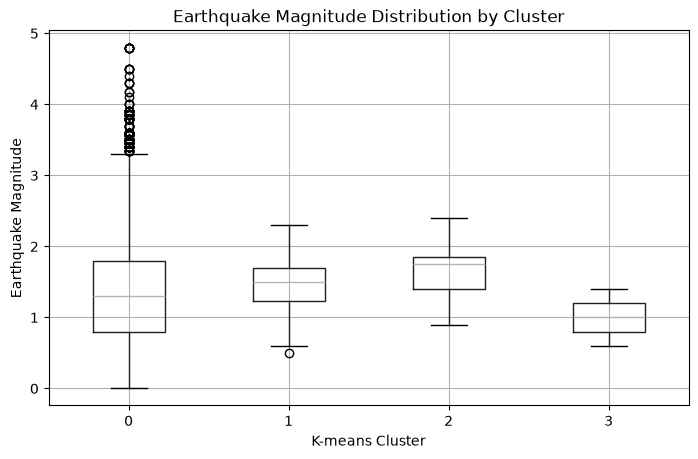

In [13]:
cluster_magnitude_df = pd.DataFrame({"Cluster": cluster_labels,
                                     "Magnitude": magnitude[valid].to_numpy()})
cluster_magnitude_df.boxplot(column = "Magnitude",
                             by = "Cluster",
                             figsize = (8, 5))

plt.title("Earthquake Magnitude Distribution by Cluster")
plt.suptitle("")
plt.xlabel("K-means Cluster")
plt.ylabel("Earthquake Magnitude")
plt.show()

From this, we can see that there is one main cluster, then a small group of outliers, and a few outliers not near either the main cluster nor the smaller outleir cluster. Additionally, there is no strong elbow to select the best value of k. Due to this, I picked a k value of 4, since this was within the elbow of the k-means plot as well as the highest silhouette analysis value. 

Additionally, our homogeneity score of nearly 0 tells us that our clusters contain a wide range of values within each category. Due to this, we can infer that these clusters do not help us predict the true values of the data within the clusters. Our Fowlkes-Mallows Index also tells us that our clusters correctly groups some of the data, but either splits groups that should be together or puts points into groups they do not belong to. 

Next, we looked at the adjusted random index, which was between .8 and 1 (with a mean of .97) for all 100 iterations of the k-means splits. This implies that our model does not vary much between iterations. Due to this, if the clustering was good we would be able to use it in the future since it is consistent. 

Finally, the plots showing the k-means clusters and earthquake magnitudes by waveform as well as the boxplot of magnitude by cluster highlight how poorly our model is at predicting magnitude. Every cluster appears to have a similar distribution of magnitudes with no clear pattern distuingishing magnitudes from waveforms. 